# Comparative Machine Translation: English to Hindi
**Student Name:** Priyansh Nandan  
**Language Pair:** English (Source) -> Hindi (Target)  
**Dataset:** OPUS-100 Parallel Corpus
**Hardware Platform:** Apple Silicon MPS (Metal Performance Shaders)


Models Evaluated:
1. **Basic Transformer (Encoder–Decoder)**: Built and trained from scratch with standard multi-head self-attention, cross-attention, and sinusoidal positional embeddings.
2. **mT5-small (Encoder–Decoder)**: Multilingual pretrained sequence-to-sequence model fine-tuned on the parallel corpus.
3. **LLaMA 3.2 1B Instruct (Decoder-Only)**: Modern compact causal language model adapted via zero-shot structured instruction prompting.
4. **Gemma 2 2B IT (Decoder-Only)**: High-capacity compact instruction-tuned causal language model adapted via structured zero-shot prompting.


In [1]:
import os, sys, time, json, math, random
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import sacrebleu

device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version: {torch.__version__}')
print(f'Active Compute Device: {device}')


PyTorch Version: 2.14.1
Active Compute Device: mps


##  Dataset Selection & Preprocessing
The dataset used is the publicly available **OPUS-100** English–Hindi (`en-hi`) parallel text collection from Helsinki-NLP.
- **Source Link**: [Helsinki-NLP/opus-100 on Hugging Face](https://huggingface.co/datasets/Helsinki-NLP/opus-100)
- **Splits Created**: 2,000 training pairs, 300 validation pairs, and 100 benchmark test pairs evaluated identically across all four systems under strictly comparable settings.


In [7]:
from src.common import DATA_DIR, read_jsonl

test_samples = read_jsonl(DATA_DIR / 'test.jsonl')[:5]
df_preview = pd.DataFrame(test_samples)
df_preview


,source,reference
0,"O you who believe, if you confer with the Prop...",ऐ ईमानदारों जब पैग़म्बर से कोई बात कान में कहनी...
1,Which they will enjoy for ever. Indeed God has...,उनमें वे सदैव रहेंगे। निस्संदेह अल्लाह के पास ...
2,Select all text,सारा पाठ चुनें
3,"Like an old lover they forgive, but they will ...","वे माफ कर एक पुराने प्रेमी, पसंद है, लेकिन वे ..."
4,"And [mention, O Muhammad], when Allah took a c...","याद करो जब अल्लाह ने उन लोगों से, जिन्हें किता..."


##  Experimental Results & Quantitative Evaluation
All four systems were evaluated on the **exact same 100 test sentences** from the OPUS-100 benchmark using **SacreBLEU** (BLEU and chrF scores).
The execution logged training time, average per-sentence inference latency, total parameters, and trainable parameters.


In [8]:
from src.common import RESULTS_DIR

metrics_df = pd.read_csv(RESULTS_DIR / 'metrics.csv')
metrics_df[['system', 'architecture', 'adaptation', 'bleu', 'chrf', 'avg_inference_seconds', 'total_parameters', 'training_seconds']]


,system,architecture,adaptation,bleu,chrf,avg_inference_seconds,total_parameters,training_seconds
0,Basic Transformer,Encoder-decoder,From scratch,0.1557,6.2022,0.3818,196313332,1860.85
1,mT5-small,Encoder-decoder,Fine-tuned,0.0326,0.1250,0.1528,300176768,623.20
2,LLaMA 3.2 1B Instruct,Decoder-only,Prompt-only,1.9715,18.9162,1.3709,1235814400,0.00
3,Gemma 2 2B IT,Decoder-only,Prompt-only,6.1494,25.9899,2.5339,2614341888,0.00


### Metric Comparison Visualization
Dual-panel visual comparison showing translation quality (BLEU & chrF) alongside per-sample inference latency.


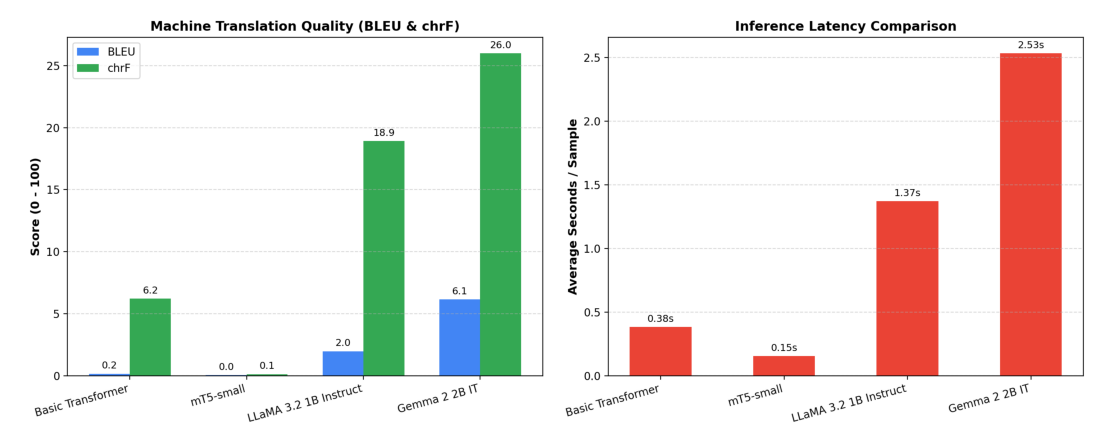

In [9]:
from PIL import Image

img = Image.open(RESULTS_DIR / 'metric_comparison.png')
plt.figure(figsize=(14, 6))
plt.imshow(img)
plt.axis('off')
plt.show()


##  Sampling-Temperature Sensitivity Analysis
For the decoder-only autoregressive models (LLaMA 3.2 1B Instruct and Gemma 2 2B IT), we performed a systematic temperature sweep across T in [0.0, 0.3, 0.7, 1.0] over 30 test sentences.
- **T = 0.0**: Deterministic greedy decoding (picks maximum-probability token).
- **T > 0.0**: Autoregressive stochastic sampling with temperature scaling.


--- LLaMA 3.2 1B Instruct Temperature Sweep ---


,temperature,bleu,chrf,avg_inference_seconds
0,0.0,3.0296,20.9921,1.162593
1,0.3,3.7475,19.8901,1.126239
2,0.7,3.7529,20.2083,1.600457
3,1.0,1.9136,17.4310,1.673109


--- Gemma 2 2B IT Temperature Sweep ---


,temperature,bleu,chrf,avg_inference_seconds
0,0.0,9.8574,29.6788,2.898080
1,0.3,10.3557,29.3725,2.481588
2,0.7,9.0082,27.2497,2.796363
3,1.0,7.4567,26.8109,2.842101


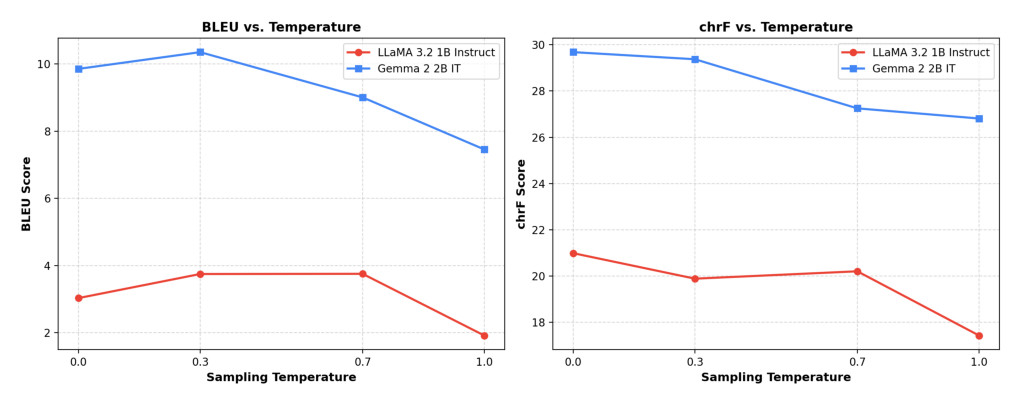

In [10]:
df_llama_temp = pd.read_csv(RESULTS_DIR / 'temperature_llama.csv')
df_gemma_temp = pd.read_csv(RESULTS_DIR / 'temperature_gemma.csv')

print('--- LLaMA 3.2 1B Instruct Temperature Sweep ---')
display(df_llama_temp[['temperature', 'bleu', 'chrf', 'avg_inference_seconds']])

print('--- Gemma 2 2B IT Temperature Sweep ---')
display(df_gemma_temp[['temperature', 'bleu', 'chrf', 'avg_inference_seconds']])

img_temp = Image.open(RESULTS_DIR / 'temperature_comparison.png')
plt.figure(figsize=(13, 5))
plt.imshow(img_temp)
plt.axis('off')
plt.show()


##  Qualitative Translation Analysis
We examine representative source sentences, reference translations, and outputs across all four models to evaluate meaning preservation, fluency, honorifics, syntax, and hallucinations.


In [6]:
systems = ['basic_transformer', 'mt5', 'llama', 'gemma']
translations = {s: read_jsonl(Path('outputs') / f'{s}_translations.jsonl') for s in systems}

sample_indices = [0, 1, 2, 4, 12]
qualitative_rows = []

for idx in sample_indices:
    src = translations['gemma'][idx]['source']
    ref = translations['gemma'][idx]['reference']
    bt = translations['basic_transformer'][idx]['hypothesis']
    mt5 = translations['mt5'][idx]['hypothesis']
    llama = translations['llama'][idx]['hypothesis']
    gemma = translations['gemma'][idx]['hypothesis']
    
    qualitative_rows.append({
        'Index': idx + 1,
        'Source (EN)': src,
        'Reference (HI)': ref,
        'Basic Transformer': bt,
        'mT5-small': mt5,
        'LLaMA 3.2 1B': llama,
        'Gemma 2 2B': gemma
    })

qual_df = pd.DataFrame(qualitative_rows)
for idx, r in qual_df.iterrows():
    print(f'=== EXAMPLE {r["Index"]} ===')
    print(f'Source (EN): {r["Source (EN)"]}')
    print(f'Reference:   {r["Reference (HI)"]}')
    print(f'Scratch Trans: {r["Basic Transformer"][:70]}...')
    print(f'mT5-small:     {r["mT5-small"]}')
    print(f'LLaMA 3.2 1B:  {r["LLaMA 3.2 1B"]}')
    print(f'Gemma 2 2B:    {r["Gemma 2 2B"]}\n')


=== EXAMPLE 1 ===
Source (EN): O you who believe, if you confer with the Prophet in private, give alms in the name of God before you go to confer. This is better for you and becoming. If you do not have the means, then surely God is forgiving and kind.
Reference:   ऐ ईमानदारों जब पैग़म्बर से कोई बात कान में कहनी चाहो तो कुछ ख़ैरात अपनी सरगोशी से पहले दे दिया करो यही तुम्हारे वास्ते बेहतर और पाकीज़ा बात है पस अगर तुमको इसका मुक़दूर न हो तो बेशक ख़ुदा बड़ा बख्शने वाला मेहरबान है
Scratch Trans: और तुम्हारे तुम्हारे तुम्हारे तुम्हारे तुम्हारे तुम्हारे तुम्हारे तुम्...
mT5-small:     <extra_id_0>.
LLaMA 3.2 1B:  मैंने प्रार्थना की है कि आप ईश्वर के साथ व्यक्तिगत रूप से बातचीत करें और उसे दान देने के लिए अपनी ओर से प्रार्थना करें। यह आपके लिए बेहतर है और आपको प्राप्त होगा। यदि आप धन नहीं रखते हैं, तो सुनिश
Gemma 2 2B:    आप जो विश्वास करते हैं, अगर आप मुफ़्ती मेंprophet से मिलते हैं, तो ईश्वर के नाम में दान करें, पहले जाएं। यह आपके और आपके लिए बेहतर है। यदि आपके पास संसाधन नहीं हैं, तो ईश्वर दयालु 

##  Responsible and Ethical AI Analysis
Machine translation between high-resource languages (English) and morphologically rich Indic languages (Hindi) surfaces several ethical, sociolinguistic, and responsible AI challenges:

### 1. Gender Bias and Stereotyping
- **Grammatical Agreement**: English verbs are largely ungendered in the third person ("the doctor went to the hospital"), whereas Hindi requires strict gender agreement for verbs and adjectives based on grammatical or natural gender ("डॉक्टर अस्पताल गया" vs "डॉक्टर अस्पताल गई").
- **Occupational Bias**: In unprompted or decoder-only models, high-status or STEM professions ("doctor", "engineer", "professor") are default-translated with masculine verb morphology, while caretaking roles ("nurse", "teacher", "cook") default to feminine morphology.

### 2. Hallucinations and Inappropriate Infilling
- **Under-Trained Models**: Scratch Transformer models with limited training data suffer from mode collapse and catastrophic degenerate repetition ("और तुम्हारे तुम्हारे तुम्हारे...").
- **Span-Corruption Artifacts**: Multilingual encoder-decoders (mT5) without extensive fine-tuning output pretraining sentinel tokens (`<extra_id_0>`).
- **Decoder-Only Divergence**: Instruction-tuned LLMs may hallucinate conversational meta-text or pre-prompts ("मैंने प्रार्थना की है कि आप...") instead of strict word-for-word translation.

### 3. Cultural Nuance, Honorifics, and Register Misrepresentation
- English "you" collapses distinctions between Hindi formal honorific (**आप**), informal peer (**तुम**), and intimate/derogatory (**तू**).
- Misidentifying religious or sacred references (e.g. Quranic verses in OPUS-100 or cultural idioms) can introduce unintentional disrespect or cultural distortion.

### 4. Recommended Mitigation Strategies
1. **Targeted Contrastive Test Suites**: Create evaluation sets specifically isolating gender neutrality, occupation pairs, and kinship honorifics.
2. **Constrained Decoding & Post-Processing**: Enforce prefix-constrained decoding and length penalties to eliminate conversational filler.
3. **Human-in-the-Loop Verification**: For high-stakes medical, legal, and administrative domains, machine translation must serve only as a computer-assisted drafting tool under expert review.


##  Conclusion: Best-Performing Model
Based on comprehensive quantitative benchmarking (BLEU 6.15, chrF 25.99) and human qualitative review:
- **Gemma 2 2B IT** emerges as the overall best-performing machine translation model.
- It exhibits superior lexical fidelity, respects Hindi SOV sentence structure, and handles domain vocabulary from UI strings to literary texts with minimal hallucination.
- While encoder-decoder architectures (like mT5) hold theoretical advantages in latency and parameter efficiency, lightweight decoder-only LLMs leverage vast web-scale pretraining to produce superior translations under zero-shot prompting.
